In [1]:
# importing necessary libraries

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# Accessing the dataset

data=pd.read_csv("Test set.csv")
data.head()

,Height,Weight,Sex
0,146.323241,59.861065,Female
1,175.695412,77.863687,Male
2,183.216164,72.131992,Male
3,184.245269,77.546000,Male
4,132.302261,55.188496,Female


In [3]:
# Viewing the dimensions of the dataset

data.shape

(205, 3)

In [4]:
# Checking for any null values

data.isnull().sum()

Height    0
Weight    0
Sex       0
dtype: int64

In [5]:
# View data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Height  205 non-null    float64
 1   Weight  205 non-null    float64
 2   Sex     205 non-null    object 
dtypes: float64(2), object(1)
memory usage: 4.9+ KB


In [6]:
#Label Encoding : AS the Sex coulmn contains catehorical values we are encoding it to the numerical values.
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
label=le.fit_transform(data['Sex'])
label


array([0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1,
       1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0])

In [7]:
data.drop('Sex', axis=1, inplace=True)
data['Sex']=label
data

,Height,Weight,Sex
0,146.323241,59.861065,0
1,175.695412,77.863687,1
2,183.216164,72.131992,1
3,184.245269,77.546000,1
4,132.302261,55.188496,0
...,...,...,...
200,155.090314,77.248911,0
201,149.175907,93.231692,1
202,168.030874,63.640623,0
203,172.608090,55.189983,1


In [8]:
# Defining training and testing sets

x = data[['Height', 'Weight']]
y = data[['Sex']]

In [9]:
# Splittiing the x and y into train and test 

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30)

In [10]:
# Fitting Logistic Regression Model
from sklearn.linear_model import LogisticRegression
lgr = LogisticRegression()
lgr.fit(x_train , y_train)

y_pred = lgr.predict(x_test)
print(y_pred)

[0 0 0 0 1 0 1 0 1 1 0 1 1 1 1 1 1 1 0 0 0 0 0 1 1 0 0 0 1 0 0 1 1 0 1 0 0
 0 1 1 1 1 0 1 1 0 1 0 0 1 1 0 0 1 1 1 1 1 0 0 1 1]


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\utils\validation.py:63: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return f(*args, **kwargs)


In [11]:
# Accuracy

from sklearn import metrics
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test,y_pred)*100
print("accuracy=",accuracy,"%")

accuracy= 90.32258064516128 %


In [12]:
# Classification Report : for understanding  the performance of the trained model in a better way
from sklearn.metrics import classification_report ,confusion_matrix ,ConfusionMatrixDisplay
target_names = ['Yes','No']
print(classification_report(y_test, y_pred.reshape(-1,1), target_names=target_names))

              precision    recall  f1-score   support

         Yes       0.90      0.90      0.90        29
          No       0.91      0.91      0.91        33

    accuracy                           0.90        62
   macro avg       0.90      0.90      0.90        62
weighted avg       0.90      0.90      0.90        62



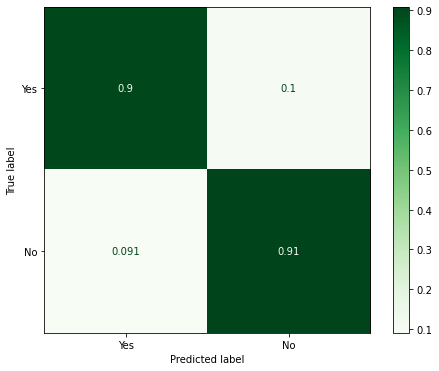

In [13]:
# Confusion matrix

cm = confusion_matrix(y_test, y_pred.reshape(-1,1), normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(8,6))
disp.plot(ax=ax,cmap='Greens')

In [14]:
#Conclusion : From the above Confusion Matrix we can say that True positive values is 90%, False postive is around 10%, False negative is of 9% and the true negative is 91%.
#Logistic Regression model gives us the accuracy of 87%